**Import**

In [ ]:
from __future__ import annotations
from pathlib import Path
from PIL import Image, UnidentifiedImageError

import jax
import optax
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import config
import data
import model
import train

import kagglehub

**Data preparation**

In [ ]:
validation_fraction = 0.1
seed = 2003
data_dir = "datasets"

path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

directory_path = path + '/PetImages/'

image_size = (128, 128)  # (W, H)

images = []
labels = []
ignored = 0

for animal in ["Cat", "Dog"]:
    image_paths = list((Path(directory_path) / animal).glob("*.jpg"))

    for image_path in tqdm(image_paths, desc=animal):
        try:
            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img = img.resize(image_size, Image.Resampling.BILINEAR)
                image_array = np.array(img, dtype=np.uint8)

        except (UnidentifiedImageError, OSError, ValueError):
            ignored += 1
            continue

        images.append(image_array)
        labels.append(0 if animal == "Cat" else 1)

images = np.stack(images)
labels = np.array(labels)

train_images, test_images, train_labels, test_labels = data._train_test_split(
                                                                            images=images,
                                                                            labels=labels,
                                                                            validation_fraction=0.1,
                                                                            seed=seed,)

dataset = data._bundle(
        train_images,
        train_labels,
        test_images,
        test_labels,
        validation_fraction,
        seed,)

**Inspect the dataset**

Train dataset size : 20248
Image size : (128, 128, 3)


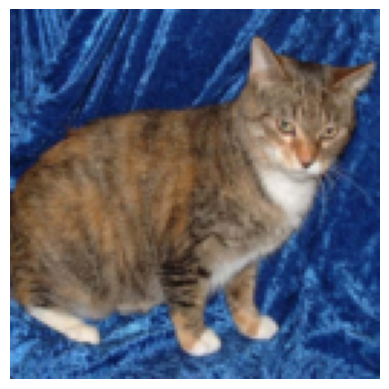

In [3]:
print(f"Train dataset size : {dataset.train.size}")
print(f"Image size : {dataset.train.images.shape[1:]}")

plt.imshow(dataset.train.images[30,:,:])
plt.axis('off')
plt.show()

**Model prep**

In [13]:
batch_size = 128
epochs = 30
lr = 3e-4
weight_decay = 3e-4

data_config = config.DataConfig(
        name="bhavikjikadara",
        data_dir=data_dir,
        validation_fraction=validation_fraction,
        batch_size=batch_size,
        seed=seed,
    )

training_config = config.TrainingConfig(
        epochs=epochs,
        learning_rate=lr,
        weight_decay=weight_decay,
        seed=seed,
    )

model_config = config.ModelConfig(
    depths= (2, 2),
    dims=(64, 128),
    num_classes=2,
    drop_path_rate=0.2,
)

experiment = config.ExperimentConfig(
    data=data_config,
    model=model_config,
    training=training_config,
)

key = jax.random.key(experiment.training.seed)
key, subkey = jax.random.split(key)
params = model.init_cnn(subkey, dataset.input_shape, experiment.model)

optimizer = optax.adamw(
        learning_rate=experiment.training.learning_rate,
        weight_decay=experiment.training.weight_decay,
    )

state = train.create_state(params, optimizer)
forward_fn = model.build_forward_fn(experiment.model)

parameter_count = sum(leaf.size for leaf in jax.tree_util.tree_leaves(params))
print(
        f"Dataset: {experiment.data.name} | input: {dataset.input_shape} | "
        f"classes: {dataset.num_classes} | parameters: {parameter_count:,}"
    )


Dataset: bhavikjikadara | input: (128, 128, 3) | classes: 2 | parameters: 389,442


**Training**

100%|██████████| 30/30 [07:34<00:00, 15.15s/it]


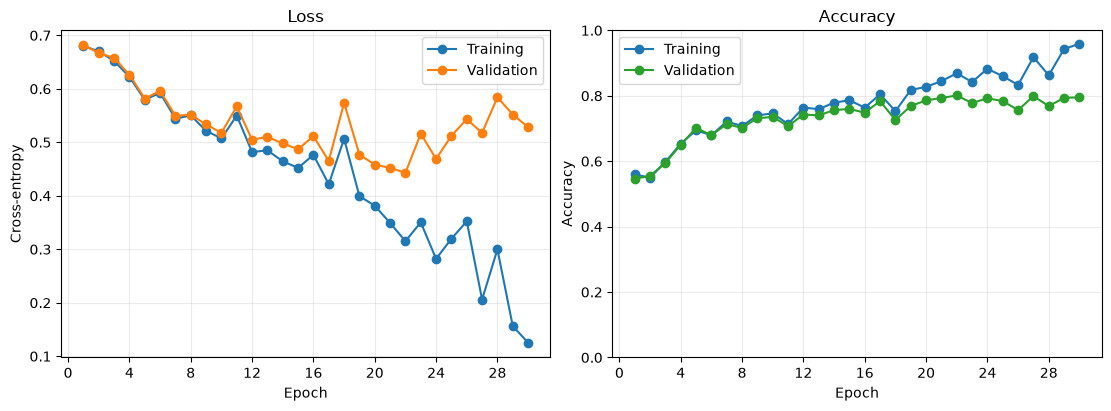

PosixPath('results/cats_dogs/metrics.png')

In [14]:
output_dir = Path("results/cats_dogs")

key, subkey = jax.random.split(key)

state, history = train.fit(
        state=state,
        train_split=dataset.train,
        validation_split=dataset.validation,
        forward_fn=forward_fn,
        optimizer=optimizer,
        epochs=experiment.training.epochs,
        batch_size=experiment.data.batch_size,
        key=subkey,
        show_progress=True,
        output_dir=output_dir,
    )

train.plot_metrics(history, output_path=output_dir / "metrics.png", show=True)

In [15]:
checkpoint = train.load_checkpoint(output_dir / "best_checkpoint.pkl")
best_state = checkpoint["state"]
print(f"Best validation epoch: {checkpoint['epoch']}")

test_metrics = train.evaluate(
        params=best_state.params,
        split=dataset.test,
        forward_fn=forward_fn,
        batch_size=experiment.data.batch_size,
    )
print(
        f"Test loss: {test_metrics['loss']:.4f} | "
        f"test accuracy: {test_metrics['accuracy']:.2%}"
    )

Best validation epoch: 22
Test loss: 0.4493 | test accuracy: 78.40%


**Testing with a real image**

In [18]:
best_params = best_state.params

test_img = []

test_img_paths = [#"data/kumcat_96.jpg","data/uzi_96.jpg","data/romain_96.jpg",
                    ]
if len(test_img_paths) > 0:
    for image_path in test_img_paths:
        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.resize(image_size, Image.Resampling.BILINEAR)
            image_array = np.array(img, dtype=np.float32)

        test_img.append(image_array)

    test_img = np.stack(test_img)

    test_img = data._prepare_images(test_img)

    logits = model.apply_cnn(
                params=best_params,
                images=test_img,
                training=False,
            )

    results = jax.nn.softmax(logits)[:,0]

    for idx, img in enumerate(test_img):
        prob = results[idx]
        label = 'Dog' if prob <= 0.5 else 'Cat'
        confidence = (1 - prob) if prob <= 0.5 else prob
        plt.imshow(img)
        plt.title(f"Is a {label} with {confidence:.2%} confidence")
        plt.axis('off')
        plt.show()